In [32]:
import numpy as np
import matplotlib.pyplot as plt

In [33]:
t_half = 10             #half life
lam = np.log(2)/t_half
p = 1 - np.exp(-lam)                 # Decay Probability, dt = 1
q = 1 - p               # Survival Probability

In [34]:
N = 1000                # Initial Number of atoms

In [35]:
def decay(N):
  population = []
  for t in range(100):
    r = np.random.random(N)
    survive = np.sum(r < q)         #No. of atoms survived
    population.append(survive)
    N = survive                     #Upgrade for next time step
  return population

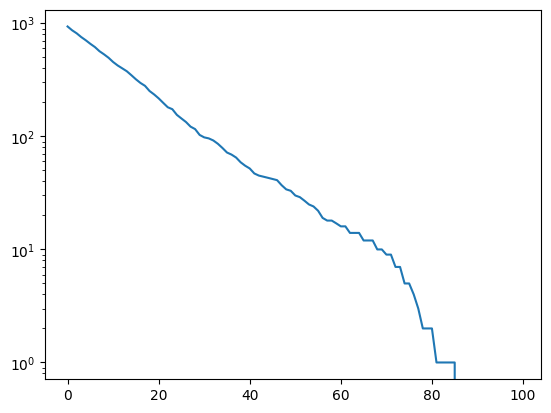

In [36]:
plt.semilogy()
plt.plot(range(100), decay(N))

In [37]:
runs = np.array([decay(N) for i in range(1000)])
mean_decay = np.mean(runs, axis = 0)
std_decay = np.std(runs, axis = 0)

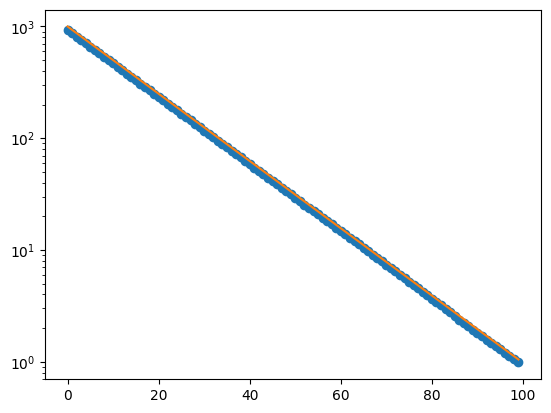

In [38]:
plt.semilogy()
T = np.arange(100)
plt.plot(T, mean_decay, 'o')
exact = N*np.exp(-lam*T)
plt.plot(T, exact)

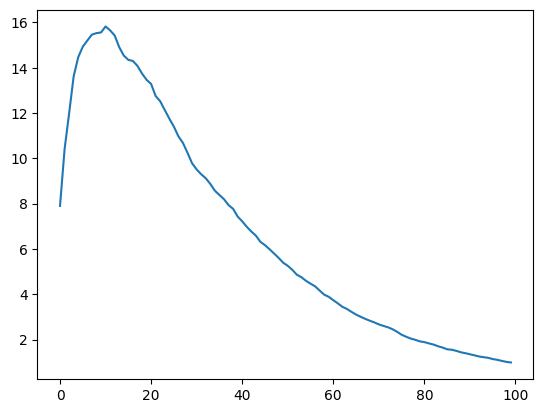

In [39]:
plt.plot(T, std_decay)

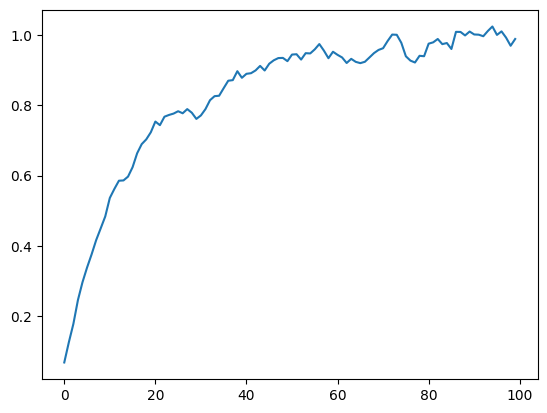

In [40]:
plt.plot(T, std_decay**2/mean_decay)

In [41]:
def run(p, record_start, runs=1000):
    q = 1 - p
    results = []
    for _ in range(runs):
        n = N
        pop = []
        for t in range(100):
            if record_start: pop.append(n)
            n = np.sum(np.random.random(n) < q)
            if not record_start: pop.append(n)
        results.append(pop)
    return np.mean(results, axis=0)

def measure(mean):
    mask = mean > 10
    slope = np.polyfit(T[mask], np.log(mean[mask]), 1)[0]
    half_life = np.log(2) / -slope
    exact = N * np.exp(-lam * T)
    error = np.mean(np.abs(mean[mask] - exact[mask]) / exact[mask]) * 100
    return half_life, error

versions = [("Original tutorial", lam, False),
            ("Fixed decay chance", 1 - np.exp(-lam), False),
            ("Both fixes", 1 - np.exp(-lam), True)]

for label, p_val, start in versions:
    hl, err = measure(run(p_val, start))
    print(f"{label}: half-life = {hl:.2f} steps, mean error = {err:.1f}%")

Original tutorial: half-life = 9.68 steps, mean error = 13.5%
Fixed decay chance: half-life = 10.02 steps, mean error = 6.3%
Both fixes: half-life = 10.03 steps, mean error = 0.6%


1,000 atoms: half-life = 10.00 steps, mean error = 0.25%, spread at the half-life = 3.2% of the average
10,000 atoms: half-life = 9.99 steps, mean error = 0.18%, spread at the half-life = 1.0% of the average


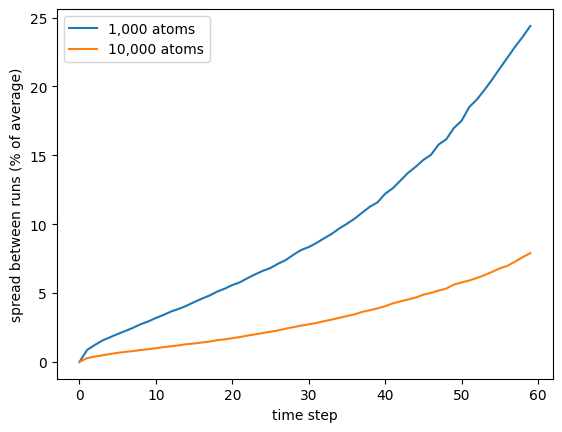

In [42]:
def run_atoms(n0, runs=1000):
    q = np.exp(-lam)                      # exact survival chance (same as 1 - p)
    results = []
    for _ in range(runs):
        n = n0
        pop = []
        for t in range(100):
            pop.append(n)                 # record before decay (Phase 5 fix)
            n = np.sum(np.random.random(n) < q)
        results.append(pop)
    return np.array(results)

spread = {}
for n0 in [1000, 10000]:
    data = run_atoms(n0)
    mean = data.mean(axis=0)
    std = data.std(axis=0)
    exact = n0 * np.exp(-lam * T)
    mask = mean > 10
    slope = np.polyfit(T[mask], np.log(mean[mask]), 1)[0]
    half_life = np.log(2) / -slope
    error = np.mean(np.abs(mean[mask] - exact[mask]) / exact[mask]) * 100
    rel = std[10] / mean[10] * 100       # spread at one half-life, as % of the average
    spread[n0] = std / mean * 100
    print(f"{n0:,} atoms: half-life = {half_life:.2f} steps, mean error = {error:.2f}%, "
          f"spread at the half-life = {rel:.1f}% of the average")

plt.plot(T[:60], spread[1000][:60], label="1,000 atoms")
plt.plot(T[:60], spread[10000][:60], label="10,000 atoms")
plt.xlabel("time step")
plt.ylabel("spread between runs (% of average)")
plt.legend()